# Волна на стыке двух материалов

В зелёной работе мы измерили амплитуды отражённого и прошедшего импульсов. Теперь сравним профили по всей длине стержня и посчитаем, какая часть начальной энергии уходит в каждую сторону.

Стык расположен в $b=2$, длина стержня равна 4. Слева $\rho_L=E_L=1$. Справа возьмём четыре пары $(\rho_R,E_R)$ из условия. Начальный импульс $g(x)$ движется вправо со скоростью $c_L=1$.


## Коэффициенты и точный профиль

Пусть $p(t)=g(b-c_Lt)$ — перемещение падающей волны на стыке. Перемещения отражённой и прошедшей волн в той же точке равны $R_u p(t)$ и $T_u p(t)$. Из непрерывности перемещения следует $1+R_u=T_u$.

Для волны, бегущей вправо, $Eu_x=-Z u_t$, а для волны, бегущей влево, $Eu_x=Z u_t$, где $Z=E/c=\rho c$. Поэтому равенство усилий на стыке даёт $-Z_L+Z_L R_u=-Z_R T_u$. Решаем два уравнения:
$$R_u=\frac{Z_L-Z_R}{Z_L+Z_R},\qquad T_u=\frac{2Z_L}{Z_L+Z_R}.$$

На всём стержне до прихода волн к закреплённым концам решение имеет вид
$$
u(x,t)=\begin{cases}
g(x-c_Lt)+R_u g(2b-x-c_Lt), & x\le b,\\[2mm]
T_u g\!\left(b+\dfrac{c_L}{c_R}(x-b)-c_Lt\right), & x>b.
\end{cases}
$$
Стык начинает взаимодействовать с импульсом при $t=0.75$ и завершает взаимодействие при $t=1.25$. К $t=1.5$ волны разделились. Даже самая быстрая прошедшая волна ($c_R=2$) к этому моменту дошла только до $x=3.5$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import re

plt.rcParams.update({
    "figure.dpi": 85,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

b = 2.0
a = 0.25
rho_L = E_L = c_L = Z_L = 1.0
materials = [(1, 4), (4, 1), (4, 0.25), (4, 4)]
sizes = [200, 400, 800]
observation_times = [0.5, 1.0, 1.5]
frame_interval = 0.025
end_time = observation_times[-1]
frame_times = np.arange(round(end_time / frame_interval) + 1) * frame_interval
panel_colors = ["#2563eb", "#df7620", "#21855b", "#8848b8"]


def pulse(x):
    angle = np.pi * (x - 1) / (2*a)
    return np.where(np.abs(x - 1) < a, np.cos(angle)**4, 0.0)


def pulse_derivative(x):
    angle = np.pi * (x - 1) / (2*a)
    return np.where(np.abs(x - 1) < a, -(2*np.pi/a) * np.cos(angle)**3 * np.sin(angle), 0.0)


def coefficients(material):
    rho_R, E_R = material
    c_R = np.sqrt(E_R/rho_R)
    Z_R = rho_R*c_R
    R = (Z_L - Z_R)/(Z_L + Z_R)
    T = 2*Z_L/(Z_L + Z_R)
    return c_R, Z_R, R, T


def exact(x, t, material):
    c_R, _, R, T = coefficients(material)
    left = pulse(x - c_L*t) + R*pulse(2*b - x - c_L*t)
    right = T*pulse(b + (c_L/c_R)*(x - b) - c_L*t)
    return np.where(x <= b, left, right)


def material_name(material):
    rho_R, E_R = material
    return f"ρᵣ={rho_R:g}, Eᵣ={E_R:g}"


## Конечные элементы и энергия

Используем линейные элементы, диагональную массу и скоростной метод Верле. От каждого элемента в соседние узлы поступает по $\rho_e h/2$. Это построчная сумма локальной матрицы массы. Складываем вклады на полной сетке и затем закрепляем концы. Стык совпадает с одним общим узлом.

Для каждого материала выбираем постоянный шаг $\Delta t\leq0.4h/\max(c_L,c_R)$. Подбираем его так, чтобы кадры через $0.025$ попадали на временную сетку. При удвоении $N$ уменьшаем $h$ и $\Delta t$ вдвое.

Энергию считаем по элементам на одном временном слое:
$$H_e=\frac{\rho_e h}{4}(V_i^2+V_{i+1}^2)+\frac{E_e}{2h}(U_{i+1}-U_i)^2.$$
Суммируем отдельно по обе стороны стыка. Скорость общего узла входит в энергию каждого соседнего элемента с весом его половины массы.


In [2]:
def simulate(N, material):
    rho_R, E_R = material
    c_R, _, _, _ = coefficients(material)
    x = np.linspace(0.0, 4.0, N + 1)
    h = 4.0/N
    left_element = (x[:-1] + x[1:])/2 < b
    rho = np.where(left_element, rho_L, rho_R)
    E = np.where(left_element, E_L, E_R)

    # Сборка диагональной массы и применение K через усилия элементов.
    element_mass = rho*h/2
    mass = np.zeros(N + 1)
    mass[:-1] += element_mass
    mass[1:] += element_mass
    stiffness = E/h

    coarse_h = 4.0/sizes[0]
    max_dt_coarse = 0.4*coarse_h/max(c_L, c_R)
    steps_per_frame = int(np.ceil(frame_interval/max_dt_coarse)) * (N//sizes[0])
    dt = frame_interval/steps_per_frame
    count = (len(frame_times) - 1)*steps_per_frame
    times = np.arange(count + 1)*dt

    U = pulse(x)
    V = -c_L*pulse_derivative(x)
    accel = np.zeros_like(U)

    def acceleration():
        force = stiffness*np.diff(U)
        accel[1:-1] = np.diff(force)/mass[1:-1]

    def energies():
        elastic = 0.5*stiffness*np.diff(U)**2
        kinetic = 0.5*element_mass*(V[:-1]**2 + V[1:]**2)
        element_energy = kinetic + elastic
        return element_energy[left_element].sum(), element_energy[~left_element].sum()

    profiles = np.empty((len(frame_times), N + 1))
    energy = np.empty((count + 1, 2))
    profiles[0] = U
    energy[0] = energies()
    acceleration()
    for step in range(1, count + 1):
        V[1:-1] += 0.5*dt*accel[1:-1]
        U[1:-1] += dt*V[1:-1]
        acceleration()
        V[1:-1] += 0.5*dt*accel[1:-1]
        energy[step] = energies()
        if step % steps_per_frame == 0:
            profiles[step//steps_per_frame] = U

    return {"x": x, "dt": dt, "times": times, "U": profiles, "energy": energy}


runs = {(material, N): simulate(N, material) for material in materials for N in sizes}


## Профили до, во время и после прохождения стыка

Сравним одно и то же движение при $t=0.5$, $1$ и $1.5$. На графиках возьмём $N=200$, чтобы различия были заметнее. Ошибку ниже считаем в узлах по всему стержню, включая стык.
 Серые линии отмечают положение стыка.


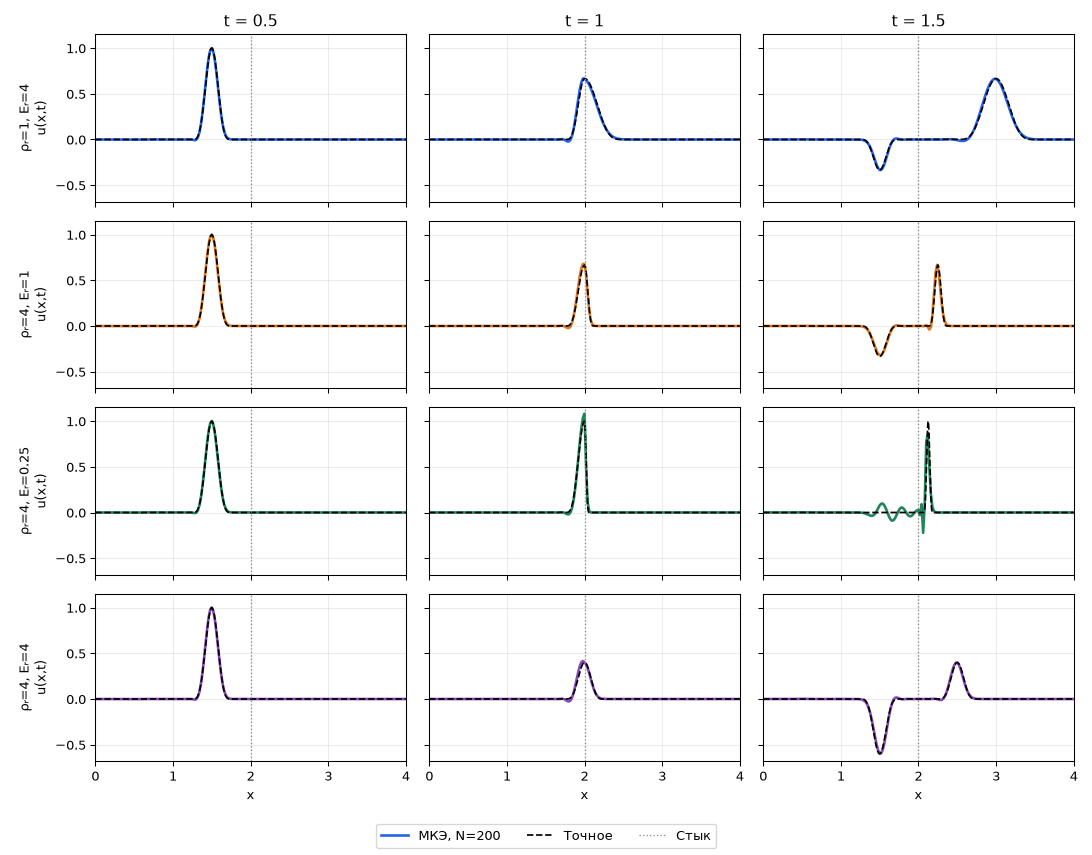

   ρᵣ     Eᵣ     cᵣ     Zᵣ        Rᵤ        Tᵤ
    1      4      2      2   -0.3333    0.6667
    4      1    0.5      2   -0.3333    0.6667
    4   0.25   0.25      1    0.0000    1.0000
    4      4      1      4   -0.6000    0.4000


In [3]:
def profile_at(result, t):
    index = int(round(t/frame_interval))
    return result["U"][index]


coarse_profiles = [runs[m, sizes[0]]["U"] for m in materials]
profile_limits = (min(u.min() for u in coarse_profiles) - 0.07,
                  max(u.max() for u in coarse_profiles) + 0.07)
dense_x = np.linspace(0, 4, 1601)
fig, axes = plt.subplots(4, 3, figsize=(11.5, 9), sharex=True, sharey=True)
for row, material in enumerate(materials):
    result = runs[material, sizes[0]]
    for col, t in enumerate(observation_times):
        ax = axes[row, col]
        ax.plot(result["x"], profile_at(result, t), color=panel_colors[row], lw=2, label="МКЭ, N=200")
        ax.plot(dense_x, exact(dense_x, t, material), "k--", lw=1.3, label="Точное")
        ax.axvline(b, color="0.55", ls=":", lw=1, label="Стык")
        if row == 0:
            ax.set_title(f"t = {t:g}")
        if col == 0:
            ax.set_ylabel(f"{material_name(material)}\nu(x,t)")
        if row == 3:
            ax.set_xlabel("x")
        ax.set(xlim=(0, 4), ylim=profile_limits, xticks=np.arange(5))
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=3)
fig.tight_layout(rect=[0, 0.045, 1, 1])
plt.show()

print(f"{'ρᵣ':>5} {'Eᵣ':>6} {'cᵣ':>6} {'Zᵣ':>6} {'Rᵤ':>9} {'Tᵤ':>9}")
for material in materials:
    c_R, Z_R, R, T = coefficients(material)
    rho_R, E_R = material
    print(f"{rho_R:5g} {E_R:6g} {c_R:6g} {Z_R:6g} {R:9.4f} {T:9.4f}")


У пар $(1,4)$ и $(4,1)$ одинаковый импеданс $Z_R=2$, поэтому амплитуды совпадают: $R_u=-1/3$, $T_u=2/3$. Скорости справа равны 2 и 0.5. Длительность импульса на стыке одна и та же, так что в первом случае прошедший профиль в четыре раза шире, чем во втором.

При $(4,0.25)$ импеданс совпадает с левым, хотя скорость в четыре раза меньше. На точном профиле отражённой волны нет. При $(4,4)$ скорости совпадают, но импедансы различаются. Здесь отражение самое сильное из четырёх случаев.


## Куда уходит энергия

Для бегущей волны кинетическая и упругая плотности энергии равны, а их сумма равна $\rho u_t^2$. При интегрировании по пространству $dx=c\,|dt|$, где $dt$ здесь означает интервал времени прохождения формы импульса через фиксированную точку. Поэтому энергия волны пропорциональна $Z$ и квадрату амплитуды. Получаем
$$\mathcal R=R_u^2,\qquad \mathcal T=\frac{Z_R}{Z_L}T_u^2,\qquad
\mathcal R+\mathcal T=1.$$

Численные доли считаем как $H_L(1.5)/H(0)$ и $H_R(1.5)/H(0)$. В таблице приводим обе доли на трёх сетках. Отдельно показываем относительное изменение полной энергии во времени.

Серой полосой отмечено время прохождения точного импульса через стык. Все кривые энергии показаны в общие моменты через $0.025$.


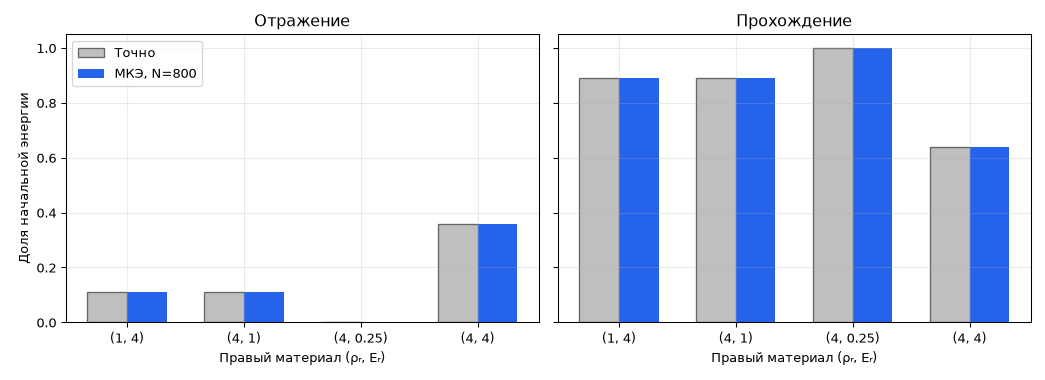

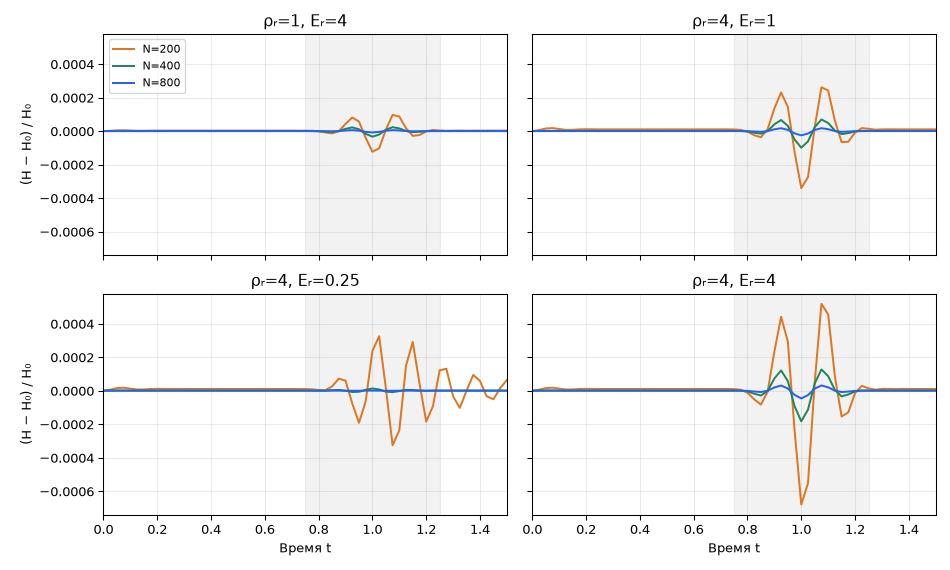

    (ρᵣ, Eᵣ)     N         Δt       H_L/H₀          ℛ       H_R/H₀          𝒯
      (1, 4)   200   0.003571   0.11397517   0.111111   0.88602769   0.888889
      (1, 4)   400   0.001786   0.11181636   0.111111   0.88818382   0.888889
      (1, 4)   800   0.000893   0.11128678   0.111111   0.88871323   0.888889
      (4, 1)   200   0.006250   0.09927814   0.111111   0.90073198   0.888889
      (4, 1)   400   0.003125   0.10826647   0.111111   0.89173419   0.888889
      (4, 1)   800   0.001563   0.11040696   0.111111   0.88959308   0.888889
   (4, 0.25)   200   0.006250   0.07204163   0.000000   0.92802257   1.000000
   (4, 0.25)   400   0.003125   0.00113831   0.000000   0.99886234   1.000000
   (4, 0.25)   800   0.001563   0.00005811   0.000000   0.99994193   1.000000
      (4, 4)   200   0.006250   0.36001234   0.360000   0.63999797   0.640000
      (4, 4)   400   0.003125   0.36000070   0.360000   0.63999995   0.640000
      (4, 4)   800   0.001563   0.36000004   0.360000   0.640000

In [4]:
def energy_fractions(result):
    H = result["energy"]
    return H[-1]/H[0].sum()


def exact_fractions(material):
    _, Z_R, R, T = coefficients(material)
    return np.array([R**2, Z_R/Z_L*T**2])


positions = np.arange(len(materials))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for side, (ax, title) in enumerate(zip(axes, ["Отражение", "Прохождение"])):
    truth = [exact_fractions(m)[side] for m in materials]
    values = [energy_fractions(runs[m, 800])[side] for m in materials]
    ax.bar(positions-0.17, truth, width=0.34, label="Точно", color="0.75", edgecolor="0.4")
    ax.bar(positions+0.17, values, width=0.34, label="МКЭ, N=800", color="#2563eb")
    ax.set(title=title, ylim=(0, 1.05), xlabel="Правый материал (ρᵣ, Eᵣ)")
    ax.set_xticks(positions, [str(m) for m in materials])
axes[0].set_ylabel("Доля начальной энергии")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

print(f"{'(ρᵣ, Eᵣ)':>12} {'N':>5} {'Δt':>10} {'H_L/H₀':>12} {'ℛ':>10} {'H_R/H₀':>12} {'𝒯':>10}")
for m in materials:
    R_exact, T_exact = exact_fractions(m)
    for N in sizes:
        result = runs[m, N]
        R_num, T_num = energy_fractions(result)
        print(f"{str(m):>12} {N:5d} {result['dt']:10.6f} {R_num:12.8f} {R_exact:10.6f} "
              f"{T_num:12.8f} {T_exact:10.6f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, material in zip(axes.flat, materials):
    for N, color in zip(sizes, ["#df7620", "#21855b", "#2563eb"]):
        result = runs[material, N]
        H = result["energy"].sum(axis=1)
        stride = int(round(frame_interval/result["dt"]))
        ax.plot(frame_times, (H[::stride] - H[0])/H[0], color=color, label=f"N={N}")
    ax.axvspan(0.75, 1.25, color="0.6", alpha=0.12)
    ax.set(title=material_name(material), xlim=(0, end_time))
axes[0, 0].legend(fontsize=8)
for ax in axes[-1, :]:
    ax.set_xlabel("Время t")
for ax in axes[:, 0]:
    ax.set_ylabel("(H − H₀) / H₀")
fig.tight_layout()
plt.show()


## Проверка при сгущении сетки

Для каждого из трёх моментов берём максимум $|U_i-u(x_i,t)|$ по всем узлам. Доли энергии сравниваем при $t=1.5$. На графике для энергий используем абсолютную ошибку каждой доли, чтобы расхождения не компенсировались при сложении.


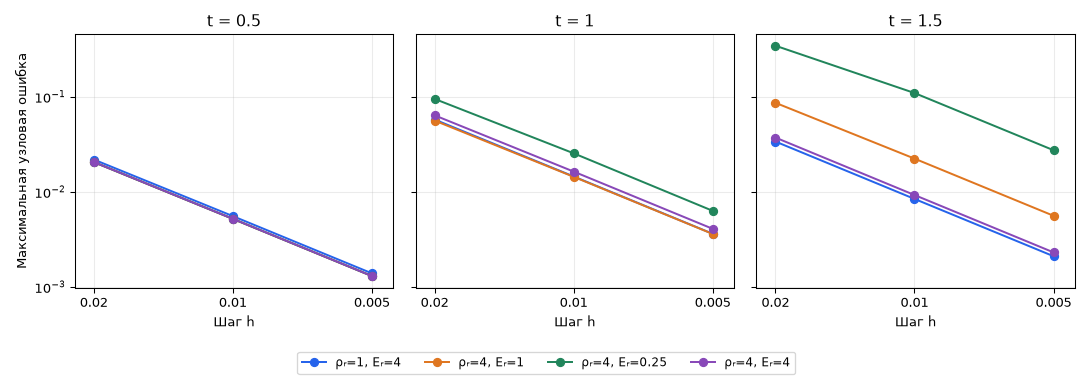

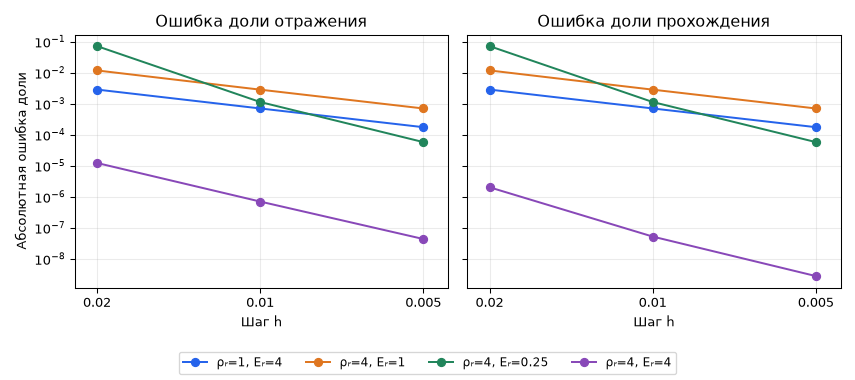

    (ρᵣ, Eᵣ)     N     e∞(0.5)       e∞(1)     e∞(1.5)        |Δℛ|        |Δ𝒯|
      (1, 4)   200   2.191e-02   5.776e-02   3.391e-02   2.864e-03   2.861e-03
      (1, 4)   400   5.567e-03   1.455e-02   8.449e-03   7.052e-04   7.051e-04
      (1, 4)   800   1.392e-03   3.629e-03   2.109e-03   1.757e-04   1.757e-04
      (4, 1)   200   2.062e-02   5.634e-02   8.667e-02   1.183e-02   1.184e-02
      (4, 1)   400   5.212e-03   1.443e-02   2.243e-02   2.845e-03   2.845e-03
      (4, 1)   800   1.304e-03   3.616e-03   5.617e-03   7.042e-04   7.042e-04
   (4, 0.25)   200   2.062e-02   9.523e-02   3.456e-01   7.204e-02   7.198e-02
   (4, 0.25)   400   5.212e-03   2.550e-02   1.099e-01   1.138e-03   1.138e-03
   (4, 0.25)   800   1.304e-03   6.328e-03   2.749e-02   5.811e-05   5.807e-05
      (4, 4)   200   2.062e-02   6.398e-02   3.734e-02   1.234e-05   2.032e-06
      (4, 4)   400   5.212e-03   1.638e-02   9.287e-03   7.047e-07   5.240e-08
      (4, 4)   800   1.304e-03   4.093e-03   2.314e-

In [5]:
profile_errors = {}
fraction_errors = {}
for material in materials:
    for N in sizes:
        result = runs[material, N]
        profile_errors[material, N] = [
            np.max(np.abs(profile_at(result, t) - exact(result["x"], t, material)))
            for t in observation_times
        ]
        fraction_errors[material, N] = np.abs(energy_fractions(result) - exact_fractions(material))

h_values = 4.0/np.array(sizes)
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4), sharey=True)
for index, (ax, t) in enumerate(zip(axes, observation_times)):
    for material, color in zip(materials, panel_colors):
        ax.loglog(h_values, [profile_errors[material, N][index] for N in sizes],
                  "o-", color=color, label=material_name(material))
    ax.set(title=f"t = {t:g}", xlabel="Шаг h")
    ax.set_xticks(h_values, [f"{h:g}" for h in h_values])
    ax.set_xlim(0.022, 0.0045)
    ax.minorticks_off()
axes[0].set_ylabel("Максимальная узловая ошибка")
fig.legend(*axes[0].get_legend_handles_labels(), ncol=4, loc="lower center", fontsize=9)
fig.tight_layout(rect=[0, 0.095, 1, 1])
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for side, (ax, title) in enumerate(zip(axes, ["Ошибка доли отражения", "Ошибка доли прохождения"])):
    for material, color in zip(materials, panel_colors):
        ax.loglog(h_values, [fraction_errors[material, N][side] for N in sizes],
                  "o-", color=color, label=material_name(material))
    ax.set(title=title, xlabel="Шаг h")
    ax.set_xticks(h_values, [f"{h:g}" for h in h_values])
    ax.set_xlim(0.022, 0.0045)
    ax.minorticks_off()
axes[0].set_ylabel("Абсолютная ошибка доли")
fig.legend(*axes[0].get_legend_handles_labels(), ncol=4, loc="lower center", fontsize=9)
fig.tight_layout(rect=[0, 0.095, 1, 1])
plt.show()

print(f"{'(ρᵣ, Eᵣ)':>12} {'N':>5} {'e∞(0.5)':>11} {'e∞(1)':>11} {'e∞(1.5)':>11} {'|Δℛ|':>11} {'|Δ𝒯|':>11}")
for material in materials:
    for N in sizes:
        errors = [*profile_errors[material, N], *fraction_errors[material, N]]
        print(f"{str(material):>12} {N:5d} " + " ".join(f"{e:11.3e}" for e in errors))


При сгущении сетки обе ошибки долей и ошибка профиля уменьшились у всех четырёх материалов. Самый узкий прошедший импульс получается при $(4,0.25)$. Его точная ширина $0.125$, на грубой сетке это чуть больше шести интервалов. В этом случае доля энергии слева при $t=1.5$ снижается с $7.20$% при $N=200$ до $0.0058$% при $N=800$, приближаясь к точному нулю. Узловая ошибка при этом падает с $0.346$ до $0.0275$.

## Движение импульсов

Во всех четырёх панелях один момент времени и одинаковый масштаб. Вертикальная линия отмечает стык. Ширину и положение прошедшего импульса можно сравнить на последних кадрах.


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.8), sharex=True, sharey=True)
lines = []
for ax, material, color in zip(axes.flat, materials, panel_colors):
    result = runs[material, sizes[0]]
    c_R, Z_R, _, _ = coefficients(material)
    numerical, = ax.plot(result["x"], result["U"][0], color=color, lw=2, label="МКЭ, N=200")
    analytical, = ax.plot(dense_x, exact(dense_x, 0, material), "k--", lw=1.3, label="Точное")
    ax.axvline(b, color="0.55", ls=":", label="Стык")
    ax.set(title=f"{material_name(material)}   |   cᵣ={c_R:g}, Zᵣ={Z_R:g}",
           xlim=(0, 4), ylim=profile_limits, xticks=np.arange(5))
    lines.append((numerical, analytical))
for ax in axes[-1, :]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("u(x,t)")
clock = fig.suptitle("t = 0.000", y=0.99)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center",
           bbox_to_anchor=(0.5, 0.95), ncol=3, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.88])


def update(frame):
    t = frame_times[frame]
    for material, (numerical, analytical) in zip(materials, lines):
        numerical.set_ydata(runs[material, sizes[0]]["U"][frame])
        analytical.set_ydata(exact(dense_x, t, material))
    clock.set_text(f"t = {t:.3f}")


animation = FuncAnimation(fig, update, frames=len(frame_times), interval=50, repeat=False)
plt.close(fig)
html = animation.to_jshtml(default_mode="once")
html = re.sub(r'<link\b[^>]*font-awesome[^>]*>', '', html)
icons = {
    "fa fa-minus": "−", "fa fa-plus": "+", "fa fa-play": "▶", "fa fa-pause": "⏸",
    "fa fa-fast-backward": "⏮", "fa fa-step-backward": "⏪",
    "fa fa-play fa-flip-horizontal": "◀", "fa fa-step-forward": "⏩", "fa fa-fast-forward": "⏭",
}
for name, symbol in icons.items():
    html = html.replace(f'<i class="{name}"></i>', f'<span>{symbol}</span>')
display(HTML(html))


<HTML animation>

## Вывод

Волна может пройти целиком при разных скоростях. Для $(\rho_R,E_R)=(4,0.25)$ обе стороны имеют $Z=1$, поэтому $R_u=0$ и $\mathcal T=1$. Справа импульс движется со скоростью $0.25$ и занимает в пространстве вчетверо меньшую ширину.

Соотношение $1+R_u=T_u$ следует из непрерывности перемещения. В энергетическом балансе участвуют квадраты амплитуд и импедансы. Например, при $(1,4)$ отражается $1/9$ энергии, а проходит $8/9$, хотя амплитуда прошедшей волны равна $2/3$ исходной.
